In [1]:
import numpy as np
import sklearn as sk
import seaborn as sns 
import pandas as pd
import matplotlib.pyplot as plt 

In [2]:
from sklearn.model_selection import KFold

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn import metrics
from sklearn import datasets

In [3]:
from matplotlib.colors import ListedColormap

from collections import defaultdict

In [4]:
data = np.loadtxt('problem2data.txt')
data

array([[ 0.613314,  1.138547,  1.      ],
       [ 0.262046,  0.245954,  1.      ],
       [ 0.809557,  1.481712,  0.      ],
       ...,
       [-0.614421, -0.347707,  1.      ],
       [ 1.531586, -0.40873 ,  0.      ],
       [ 1.317895,  1.429511,  0.      ]])

In [5]:
X, Y = data[:, :2], data[:, -1]
n, _ = np.shape(data)
n

500

In [6]:
sc = PolynomialFeatures(degree=1)
print(X[:10])
sc.fit(X, Y)
sc.transform(X[:10])

[[ 0.613314  1.138547]
 [ 0.262046  0.245954]
 [ 0.809557  1.481712]
 [-0.718433  1.017201]
 [ 1.029742 -0.930264]
 [ 0.774779  0.4216  ]
 [-0.199856  0.834872]
 [ 1.375865  1.069579]
 [ 1.989108 -1.011556]
 [-0.824581  1.162131]]


array([[ 1.      ,  0.613314,  1.138547],
       [ 1.      ,  0.262046,  0.245954],
       [ 1.      ,  0.809557,  1.481712],
       [ 1.      , -0.718433,  1.017201],
       [ 1.      ,  1.029742, -0.930264],
       [ 1.      ,  0.774779,  0.4216  ],
       [ 1.      , -0.199856,  0.834872],
       [ 1.      ,  1.375865,  1.069579],
       [ 1.      ,  1.989108, -1.011556],
       [ 1.      , -0.824581,  1.162131]])

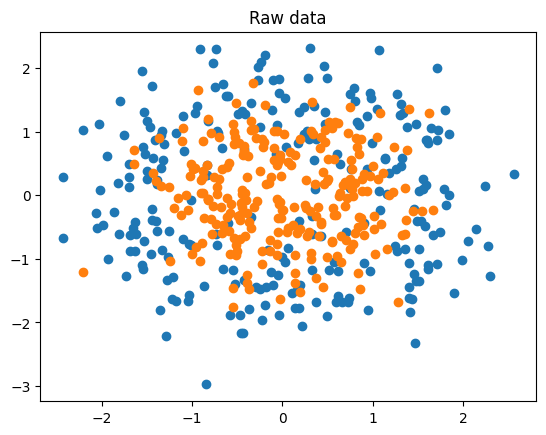

In [7]:
plt.scatter(X[Y == 0, 0], X[Y == 0, 1])
plt.scatter(X[Y == 1, 0], X[Y == 1, 1])
plt.title("Raw data")
plt.show()

In [8]:
def plot_decision_boundary(data, model, axis):
    x0,x1 = np.meshgrid(
        np.linspace(axis[0], axis[1], int((axis[1]-axis[0])*100)).reshape(-1,1),
        np.linspace(axis[2], axis[3], int((axis[3]-axis[2])*100)).reshape(-1,1)
    )
    x_new=np.c_[x0.ravel(),x1.ravel()]
    y_predict=model.predict(x_new)
    zz = y_predict.reshape(x0.shape)
    
    custom_cmap = ListedColormap(['#EF9A9A','#FFF59D','#90CAF9'])
    
    ys = data[:, 2]
    
    plt.contourf(x0, x1, zz, cmap=custom_cmap)
    plt.scatter(data[ys == 0, 0], data[ys == 0, 1])
    plt.scatter(data[ys == 1, 0], data[ys == 1, 1])
    plt.show()

In [10]:
def PolynomialLogisticRegression(deg):
    return Pipeline([
        ('poly', PolynomialFeatures(degree=deg)),
        ('std_scaler', StandardScaler()),
        ('log_reg', LogisticRegression())
    ])

Fold  0
[ 0.00681183 -0.02839414] [-0.08028791]
Fold  1
Degree:  1


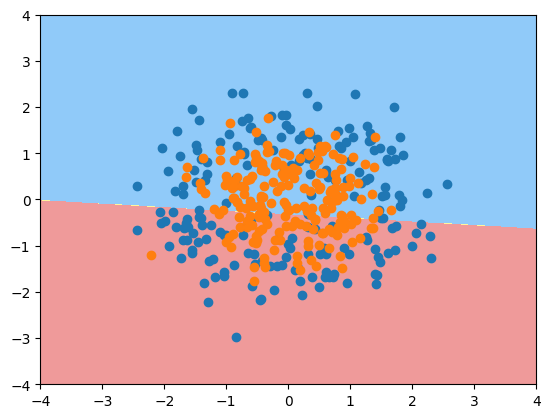

Degree:  2


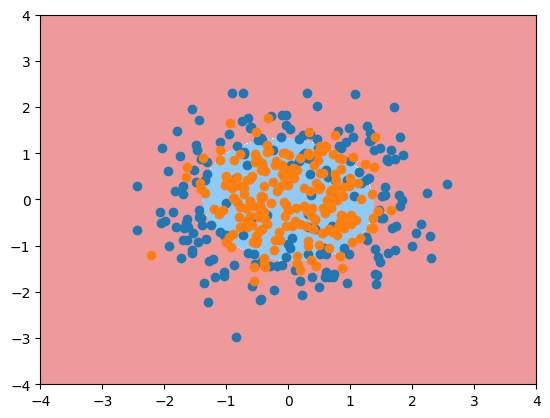

Degree:  3


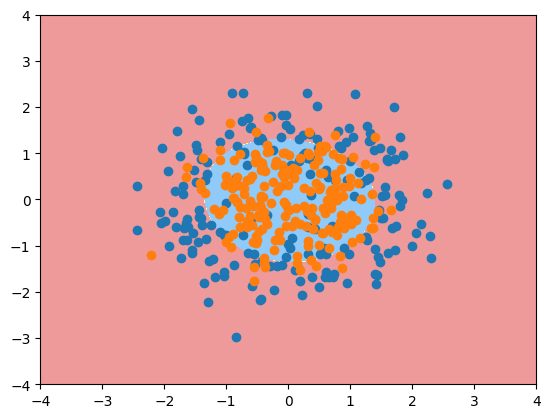

Degree:  4


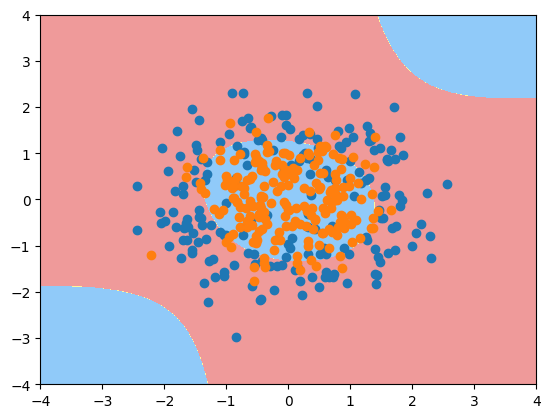

Degree:  5


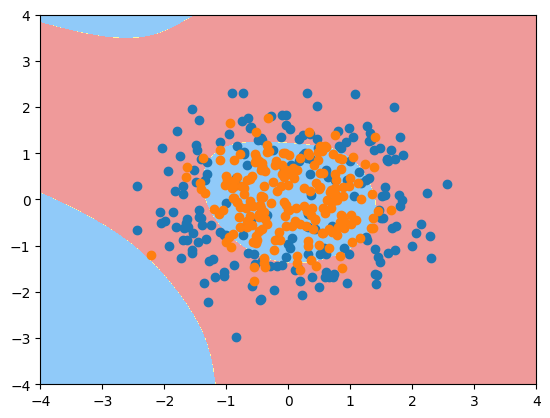

Degree:  6


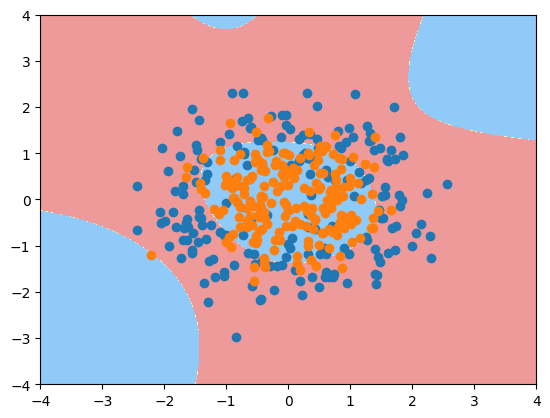

Degree:  7


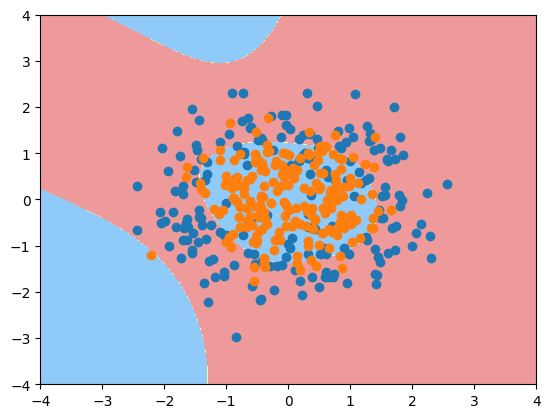

Degree:  8


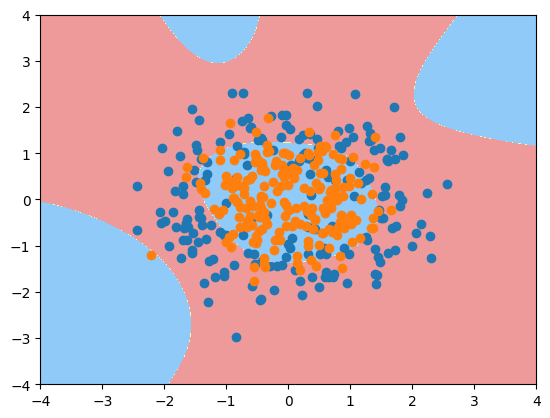

Degree:  9


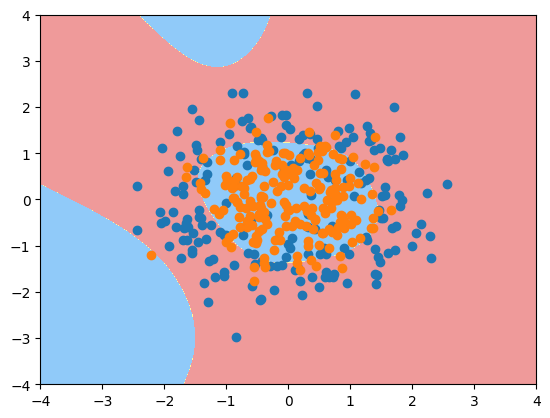

Degree:  10


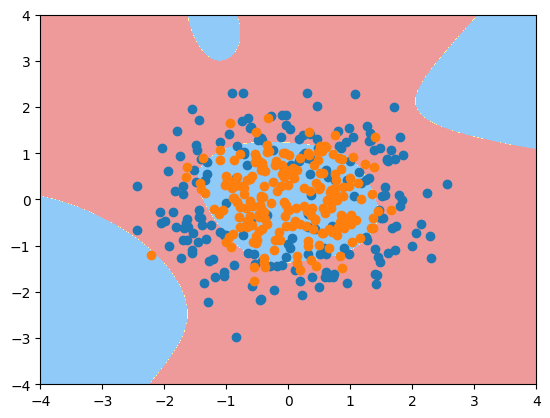

Degree:  11


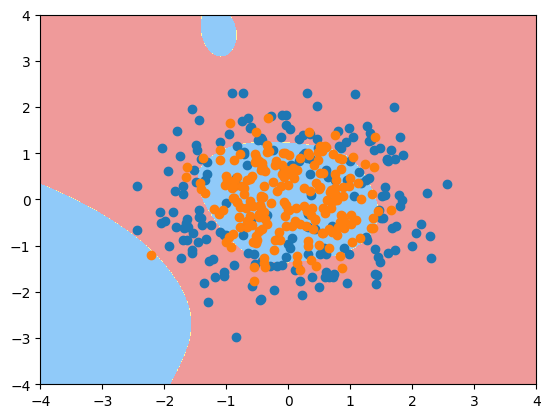

Degree:  12


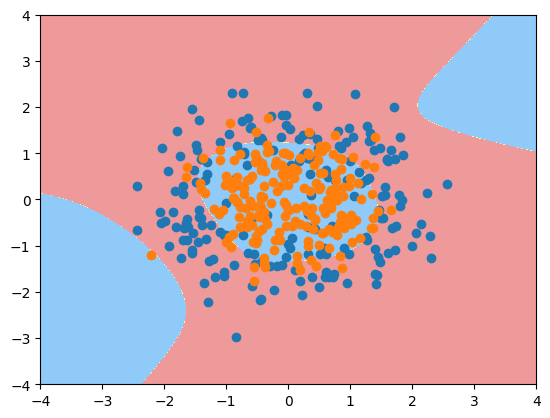

[0.00516086 0.06682614] [0.02077428]
Fold  2
[-0.00980632  0.09956165] [0.00795261]
Fold  3
[ 0.03277674 -0.0231203 ] [0.05020597]
Fold  4
[0.04805099 0.02695259] [-8.61238302e-05]


In [17]:
manually = False

i = 0
for train, test in KFold(n_splits=5).split(data):
    
    print("Fold ", i)
    i += 1
    
    X_train, Y_train = X[train], Y[train]
    X_test, Y_test = X[test], Y[test]
    
    n_train, n_test = len(X_train[:,0]), len(X_test[:, 0])
    
    if manually:
        X_train_1 = np.insert(X_train, 0, 
                              values=np.ones((np.shape(X_train)[0])), 
                              axis=1)
        X_test_1 = np.insert(X_test, 0, 
                             values=np.ones((np.shape(X_test)[0])), 
                             axis=1)
        w = np.zeros((np.shape(X_test_1)[1], 1))
        lr = 0.001
        
        for j in range(5000):
            pred_f = np.dot(X_train_1, w)
            pred_y = 1. / (1 + np.exp(-pred_f)) # sigmoid
        
            dw = (np.dot((Y_train - pred_y).T, X_train_1))
            w = w + np.dot(lr, dw.T)
        w = np.mean(w, axis=1)
        print(w)
       
    if not manually:
        if i == 2: # 
            for j in range(1, 13):
                print("Degree: ", j)

                model = PolynomialLogisticRegression(j)
                #model = LogisticRegression()
                model.fit(
                    X_train,
                    Y_train
                )
                #print(model.coef_)
                #print(model.intercept_)
                #print(model.named_steps['log_reg'].coef_[0, :] + model.named_steps['log_reg'].intercept_)
                plot_decision_boundary(data[train], model, axis=[-4, 4, -4, 4])
        
        #model = PolynomialLogisticRegression(j)
        model = LogisticRegression()
        model.fit(
            X_train,
            Y_train
        )
        print(model.coef_[0, :], model.intercept_)

## (1)

In [12]:
folds = KFold(n_splits=5, shuffle=True, random_state=5)

model = LogisticRegression()
score = cross_val_score(model, X, Y, scoring = "f1", cv=folds)
mean_score = score.mean()

print("Scores: {} \nMean: {:.4f}".format(score, mean_score))

Scores: [0.3960396  0.51785714 0.47524752 0.42424242 0.44897959] 
Mean: 0.4525


In [13]:
# same as above

folds = KFold(n_splits=5, shuffle=True, random_state=5)

model = PolynomialLogisticRegression(1)
score = cross_val_score(model, X, Y, scoring = "f1", cv=folds)
mean_score = score.mean()

print("Scores: {} \nMean: {:.4f}".format(score, mean_score))

Scores: [0.3960396  0.51785714 0.47524752 0.42424242 0.44897959] 
Mean: 0.4525


## (2)

In [14]:
folds = KFold(n_splits=5, shuffle=True, random_state=5)

means = {}
for i in range(1, 13):
    model = PolynomialLogisticRegression(i)
    score = cross_val_score(model, X, Y, scoring = "f1", cv=folds)
    means[i] = mean_score = score.mean()

    print("Degree: {} \nScores: {} \nMean: {:.4f}\n"
          .format(i, score, mean_score))

Degree: 1 
Scores: [0.3960396  0.51785714 0.47524752 0.42424242 0.44897959] 
Mean: 0.4525

Degree: 2 
Scores: [0.7628866  0.74545455 0.8952381  0.75471698 0.80392157] 
Mean: 0.7924

Degree: 3 
Scores: [0.7628866  0.72727273 0.8952381  0.75       0.82      ] 
Mean: 0.7911

Degree: 4 
Scores: [0.78787879 0.72072072 0.90384615 0.74509804 0.81553398] 
Mean: 0.7946

Degree: 5 
Scores: [0.78787879 0.72727273 0.90384615 0.75728155 0.82352941] 
Mean: 0.8000

Degree: 6 
Scores: [0.78787879 0.72727273 0.91428571 0.73076923 0.82352941] 
Mean: 0.7967

Degree: 7 
Scores: [0.78787879 0.72727273 0.8952381  0.74285714 0.81553398] 
Mean: 0.7938

Degree: 8 
Scores: [0.78787879 0.73873874 0.89719626 0.72380952 0.80392157] 
Mean: 0.7903

Degree: 9 
Scores: [0.78787879 0.73873874 0.89719626 0.72380952 0.80392157] 
Mean: 0.7903

Degree: 10 
Scores: [0.78787879 0.73873874 0.89719626 0.72897196 0.80392157] 
Mean: 0.7913

Degree: 11 
Scores: [0.78787879 0.72727273 0.89719626 0.71698113 0.80392157] 
Mean: 0.786

## (3)

In [15]:
turns = 50

means = defaultdict(int)
for k in range(turns):
    for i in range(1, 13):
        model = PolynomialLogisticRegression(i)
        folds = KFold(n_splits=5, shuffle=True)
        score = cross_val_score(model, X, Y, scoring = "f1", cv=folds)
        means[i] = means[i] + score.mean() / turns

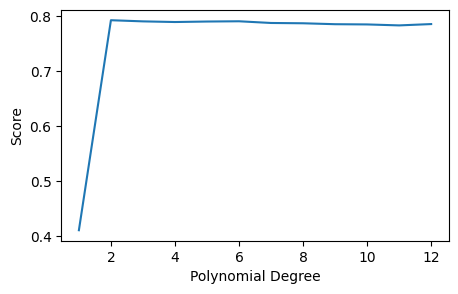

In [16]:
plt.figure(figsize=(5, 3))
plt.plot(means.keys(), means.values())
plt.xlabel("Polynomial Degree")
plt.ylabel("Score")
plt.show()